# Labels and Training Tiles

The seven Sentinel-2 scenes of 2020 and the matching hand labels are turned into training data here.

Steps: pair each scene with its label file, repair invalid polygon geometries, scale the reflectance to 8 bit, and cut everything into tiles of 384 pixels. The result is 1,001 image tiles with 1,001 matching masks in `data/training`.


# Setup

In [1]:
import sys
from pathlib import Path
import shutil

import geoai
import geopandas as gpd
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import rasterio

sys.path.append("../scripts")
from preprocessing import scale_to_byte

BASE_DIR = Path().resolve().parent if Path().resolve().name == "notebooks" else Path().resolve()
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
CLEAN_LABEL_DIR = DATA_DIR / "processed" / "labels"
SCALED_DIR = DATA_DIR / "processed" / "scaled"
TRAINING_DIR = DATA_DIR / "training"
FIGURES_DIR = BASE_DIR / "results" / "figures"

SCENE_DIR = RAW_DIR / "raster" / "sentinel2"   # talatan_2020-MM-DD.tif
LABEL_DIR = RAW_DIR / "vectors"                # own_labels_2020-MM-DD.shp

TILE_SIZE = 384
STRIDE = 384   # equal to TILE_SIZE: training tiles do not overlap

for folder in (CLEAN_LABEL_DIR, SCALED_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)


# Scenes and labels

Each 2020 scene is paired with the label file of the same date (`own_labels_YYYY-MM-DD.shp`). Scenes without a label file are skipped.

Hand-drawn polygons can contain invalid geometries, for example self-intersections after splitting features or cutting holes. The labels are therefore repaired, reprojected to the CRS of the scene and saved as cleaned copies in `data/processed/labels/`, which are used for all further steps. The overview shows the labels on top of each scene to check that they match the image of that date.

In [2]:
scenes = []

for raster_path in sorted(SCENE_DIR.glob("talatan_2020-*.tif")):
    date = raster_path.stem.replace("talatan_", "")
    vector_path = LABEL_DIR / f"own_labels_{date}.shp"

    if not vector_path.exists():
        print(f"{date}: no label file {vector_path.name}, scene is skipped")
        continue

    with rasterio.open(raster_path) as src:
        scene_crs = src.crs

    # Repair invalid geometries and keep only polygons
    labels = gpd.read_file(vector_path).to_crs(scene_crs)
    labels = labels[labels.geometry.notna() & ~labels.geometry.is_empty]
    n_invalid = int((~labels.is_valid).sum())
    labels["geometry"] = labels.geometry.make_valid()
    labels = labels.explode(index_parts=False)
    labels = labels[(labels.geom_type == "Polygon") & (labels.area > 0)].reset_index(drop=True)

    clean_path = CLEAN_LABEL_DIR / f"own_labels_{date}.gpkg"
    labels.to_file(clean_path, driver="GPKG")

    scenes.append((date, raster_path, clean_path))
    print(f"{date}: {len(labels)} polygons, {labels.area.sum() / 1e6:.1f} km², {n_invalid} repaired")

print(f"\n{len(scenes)} scenes with labels")


2020-03-11: 77 polygons, 93.3 km², 0 repaired
2020-04-15: 77 polygons, 93.4 km², 0 repaired
2020-06-29: 139 polygons, 113.5 km², 1 repaired
2020-08-20: 103 polygons, 130.8 km², 1 repaired
2020-10-07: 98 polygons, 136.7 km², 0 repaired
2020-11-13: 111 polygons, 137.3 km², 0 repaired
2020-12-23: 243 polygons, 144.8 km², 1 repaired

7 scenes with labels


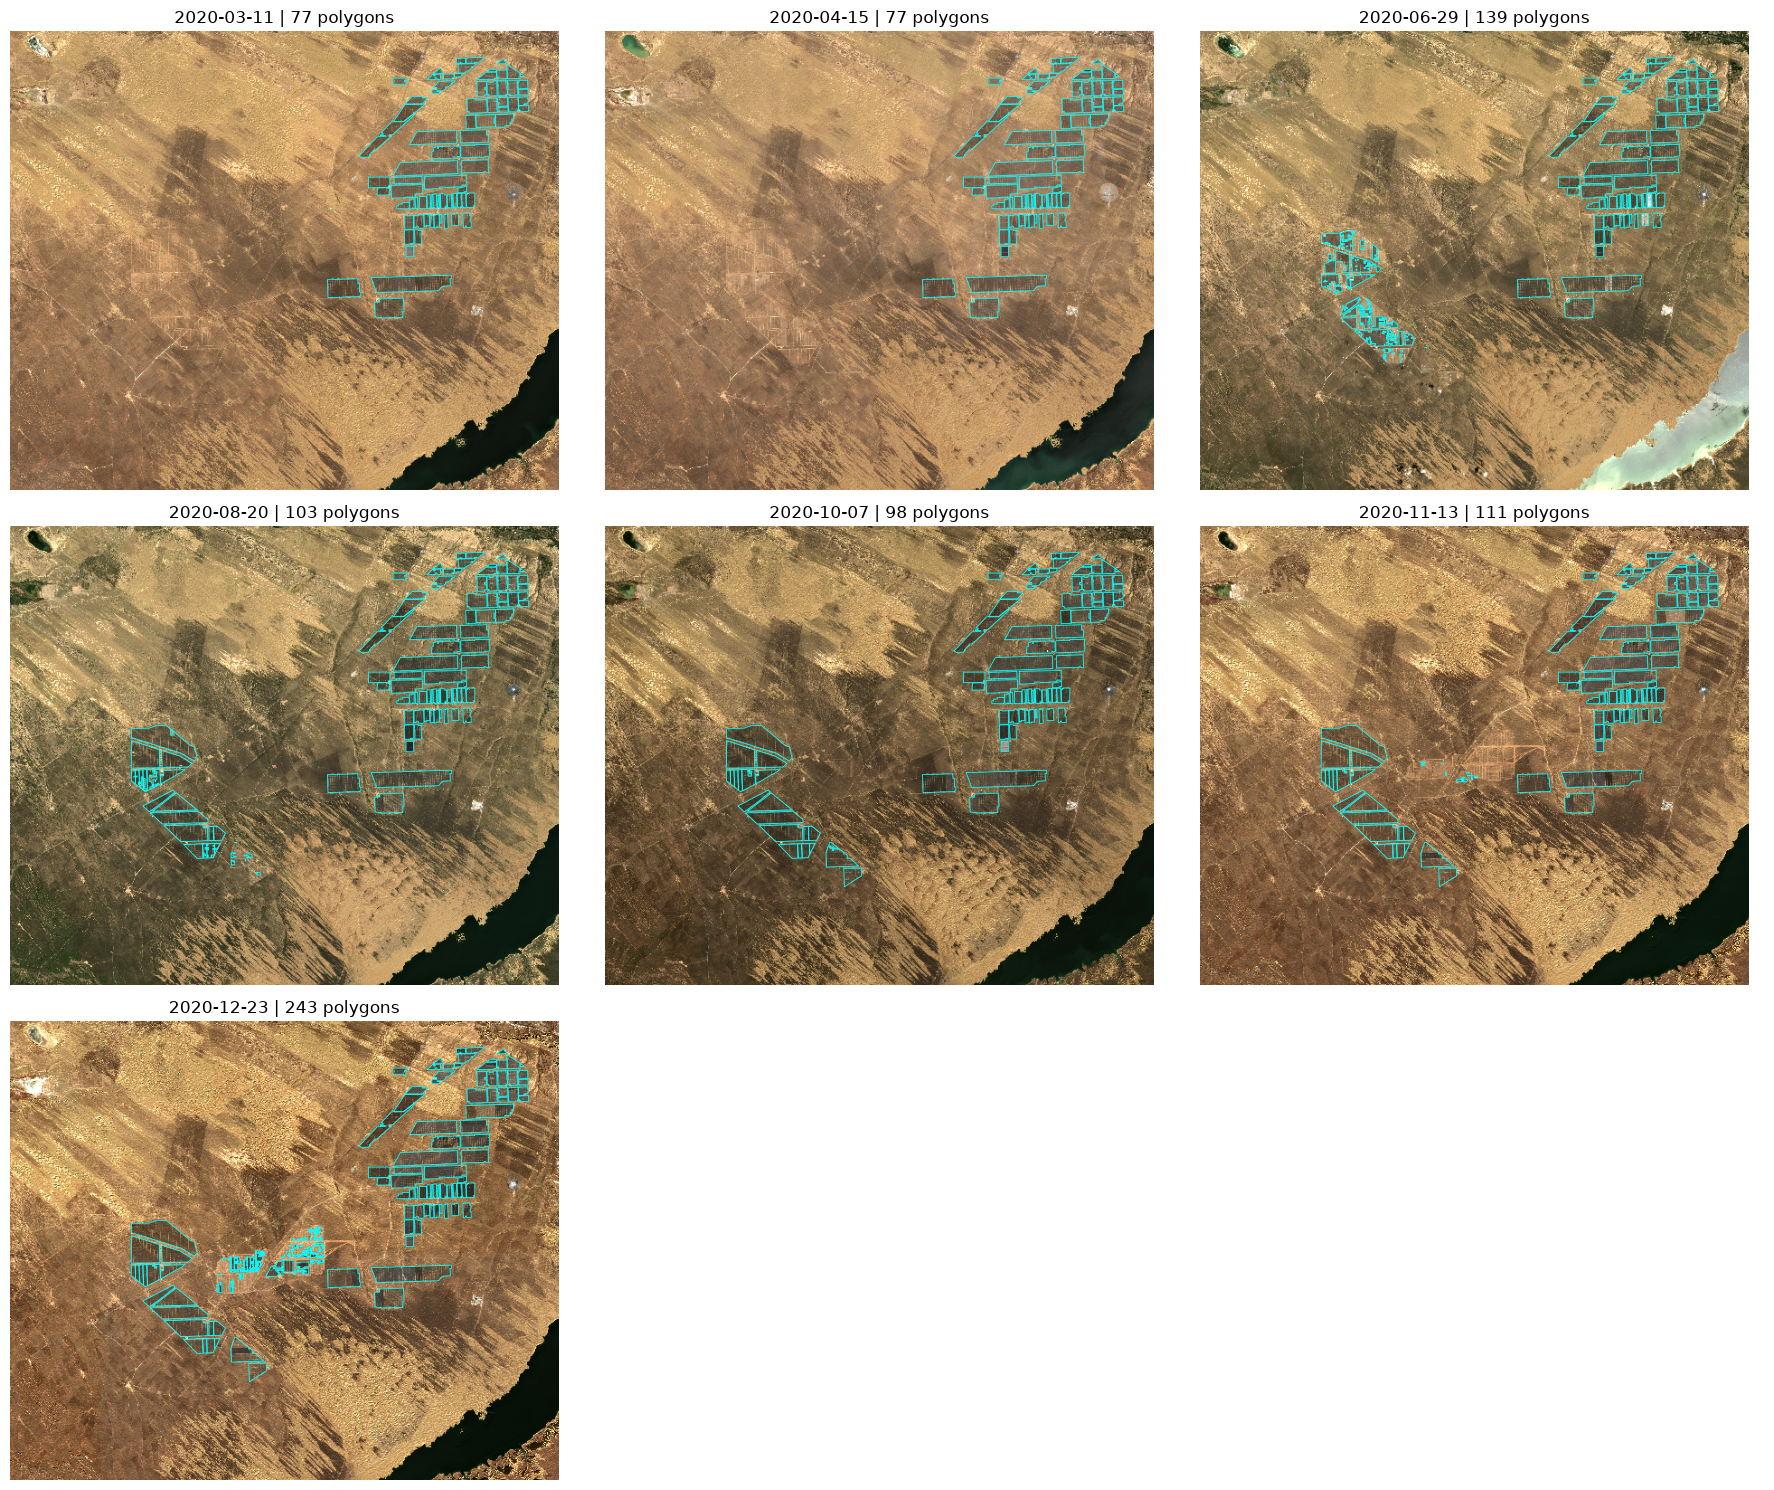

In [3]:
n_cols = 3
n_rows = int(np.ceil(len(scenes) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows), squeeze=False)

for ax in axes.flat:
    ax.axis("off")

for ax, (date, raster_path, vector_path) in zip(axes.flat, scenes):
    with rasterio.open(raster_path) as src:
        rgb = src.read([3, 2, 1], out_shape=(3, src.height // 8, src.width // 8))
        bounds, crs = src.bounds, src.crs

    labels = gpd.read_file(vector_path).to_crs(crs)

    ax.imshow(
        np.clip(np.moveaxis(rgb, 0, -1) / 10000 / 0.3, 0, 1),
        extent=[bounds.left, bounds.right, bounds.bottom, bounds.top],
    )
    labels.boundary.plot(ax=ax, color="cyan", linewidth=0.6)
    ax.set_xlim(bounds.left, bounds.right)
    ax.set_ylim(bounds.bottom, bounds.top)
    ax.set_title(f"{date} | {len(labels)} polygons")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "training_scenes_overview.png", dpi=150, bbox_inches="tight")
plt.show()


# Training data

Each scene is cut into tiles of 384 pixels without overlap, and the labels are rasterised to matching masks.

Before tiling, the reflectance values are mapped linearly from 0-4000 to 0-255. The reason is in `scripts/preprocessing.py`: geoai divides every input image by 255, which assumes 8 bit imagery. Without the mapping, Sentinel-2 values of several thousand reach the model as values between 2 and 12 instead of 0 and 1, far outside the range the ImageNet encoder was trained on, and the default brightness and contrast augmentations clip them to white. The same mapping is applied to every scene the model is later used on.

In [ ]:
if not hasattr(cm, "get_cmap"):
    cm.get_cmap = plt.get_cmap

# Start from an empty training folder so that no tiles from earlier runs remain
if TRAINING_DIR.exists():
    shutil.rmtree(TRAINING_DIR)

for kind in ("images", "labels"):
    (TRAINING_DIR / kind).mkdir(parents=True)

for date, raster_path, vector_path in scenes:
    scene_dir = TRAINING_DIR / f"scene_{date}"

    # Reflectance is mapped to 0-255 before tiling; see scripts/preprocessing.py
    scaled_path = scale_to_byte(raster_path, SCALED_DIR / f"talatan_{date}_scaled.tif")

    geoai.export_geotiff_tiles(
        in_raster=str(scaled_path),
        out_folder=str(scene_dir),
        in_class_data=str(vector_path),
        tile_size=TILE_SIZE,
        stride=STRIDE,
        buffer_radius=0,
        create_overview=False,
        quiet=True,
    )

    # Collect the tiles of all scenes in one folder; the date prefix keeps the file names unique
    for kind in ("images", "labels"):
        for tile_path in sorted((scene_dir / kind).glob("*.tif")):
            shutil.move(str(tile_path), str(TRAINING_DIR / kind / f"{date}_{tile_path.name}"))

    shutil.rmtree(scene_dir)
    print(f"{date}: tiles created")

n_images = len(list((TRAINING_DIR / "images").glob("*.tif")))
n_labels = len(list((TRAINING_DIR / "labels").glob("*.tif")))
print(f"\nTotal: {n_images} image tiles, {n_labels} label tiles")


2020-03-11: tiles created
2020-04-15: tiles created
2020-06-29: tiles created
2020-08-20: tiles created
2020-10-07: tiles created
2020-11-13: tiles created
2020-12-23: tiles created

Total: 1001 image tiles, 1001 label tiles
